Project Description

This project aims to understand the fundamentals of machine learning through linear regression, one of the most widely used algorithms in the field.

We are given a dataset composed of input variables X and target values y. The goal is to learn a function that can predict new values of y based on X.

In this case, we use a simple linear model with one variable:
y=wx+b

The objective is to find the optimal parameters w and b such that the predicted values are as close as possible to the actual values.

To achieve this, we define a loss function that measures the difference between the predicted values and the true values. We use the Mean Squared Error (MSE), which we aim to minimize.

The gradients dw and db are the partial derivatives of the loss function with respect to the parameters w and b. They indicate the direction and magnitude of the steepest increase of the loss. By updating the parameters in the opposite direction of the gradient, we iteratively reduce the error.

The learning rate controls the step size of each update and determines how quickly the model converges.

Finally, we visualize:

  1. the evolution of the regression line during training
  1. the decrease of the loss over iterations

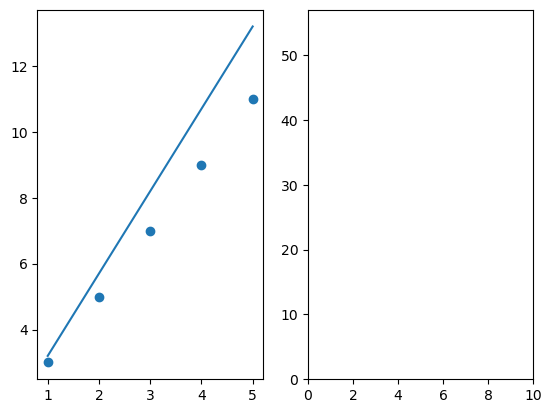

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Data
X = np.array([1, 2, 3, 4, 5])
y = np.array([3, 5, 7, 9, 11])

# Params
w, b = 0, 0
lr = 0.05
epochs = 10
n = len(X)

# Stockage
ws, bs = [], []
losses = []

for _ in range(epochs):
    y_pred = w * X + b
    loss = np.mean((y - y_pred)**2)
    losses.append(loss)
    dw = (-2/n) * np.sum(X * (y - y_pred))
    db = (-2/n) * np.sum(y - y_pred)
    
    w -= lr * dw
    b -= lr * db
    
    ws.append(w)
    bs.append(b)

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.scatter(X, y)
line, = ax1.plot(X, ws[0]*X + bs[0])

loss_line, = ax2.plot([], [])
ax2.set_xlim(0, epochs)
ax2.set_ylim(0, max(losses))

def update(frame):
    # droite
    y_line = ws[frame] * X + bs[frame]
    line.set_ydata(y_line)
    
    # loss
    loss_line.set_data(range(frame+1), losses[:frame+1])
    
    ax1.set_title(f"Epoch {frame}")
    ax2.set_title("Loss over time")
    
    return line, loss_line


ani = FuncAnimation(fig, update, frames=len(ws), interval=200)
plt.show()
from IPython.display import HTML
HTML(ani.to_jshtml())

This is the second of implementation of LinearRegression as a class.
We call the class with 5 parameters for the training part, learning rate, epochs, tolerance, seed and verbose(more details in the constructor section). And 3 others paremeters that we will use to predict new value of y based on X.
The fit method check the dimension of X, initialise the two variables, that will be updated along the epoch iteration. There is an early stoping using tolerange parameters.
The prediction method check the dimension of X for compatibility. And we use the parameters coef as the slope and the incercept.
The score method print the msen rmse nmae and r2.

Constructor
  1. Lr : learning rate ==> the step size of each update
  2. epochs : epochs ==> number of time the training data is used by the model
  3. tol : tolerance ==> treshold that decide the convergence of the model
  4. seed : seed ==> initialization of the weight and in charge of the radomness
  5. verbose : detailed logs that tracks the progress of each iteration



In [14]:
import numpy as np
class LinearRegression:
    # Constructor
    def __init__(self, lr=0.01, epochs=1000, tol=1e-6, seed = 42, verbose=False):
        self.lr = lr
        self.epochs = epochs
        self.tol = tol
        self.seed = seed
        self.verbose = verbose
        
        # learned parameters (initialized after fit)
        self.coef_= None #shape (n_features,)
        self.intercept_ = 0.0
        self.loss_history = []

    # Methods
    def fit(self, X,y):
        X = np.asarray(X)
        y = np.asarray(y)
        if X.ndim == 1:
            X = X.reshape(-1,1)
        
        n_samples, n_features = X.shape
        self.n_features_in_ = n_features

        # init 
        rng = np.random.RandomState(self.seed)
        self.coef_ = rng.randn(n_features) * 0.01
        self.intercept_ = 0.0

        prev_loss = np.inf

        for epoch in range(self.epochs):
            y_pred = X.dot(self.coef_) + self.intercept_
            residuals = y_pred - y

            # MSE loss
            loss = np.mean(residuals**2)
            self.loss_history.append(loss)

            # gradients (derivative of MSE)
            grad_w = (2.0 / n_samples) * X.T.dot(residuals) # shape (n_features,)
            grad_b = (2.0 / n_samples) * np.sum(residuals)

            # update
            self.coef_ -= self.lr * grad_w
            self.intercept_ -= self.lr * grad_b

            # tolerance-based early stopping
            if abs(prev_loss - loss ) < self.tol:
                if self.verbose:
                    print(f"Converged at epoch {epoch}, loss change {abs(prev_loss-loss): .2e}")
                    break
            prev_loss = loss

        return self           
                
    def predict(self, X):
        X = np.asarray(X)
        if X.ndim == 1:
            X = X.reshape(-1,1)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Wrong shape for X")
        return X.dot(self.coef_) + self.intercept_

    def score(self,X,y):
        y = np.asarray(y)
        y_pred = self.predict(X)
        residuals = y - y_pred
        mse = np.mean(residuals**2)
        rmse = np.sqrt(mse)
        mae = np.mean(np.abs(residuals))
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r2 = 1 - ss_res / ss_tot if ss_tot != 0 else 0.0
        return {"mse": mse, "rmse": rmse, "mae": mae, "r2":r2}

In [15]:
X = np.array([1,2,3,4,5])
y = np.array([3,5,7,9,11])

model = LinearRegression(lr=0.05, epochs=1000, tol=1e-8, seed=0, verbose=True)
model.fit(X, y)
print("coef, intercept:", model.coef_, model.intercept_)
print(model.score(X, y))


Converged at epoch 341, loss change  9.87e-09
coef, intercept: [2.00034051] 0.9987706367339426
{'mse': np.float64(2.750892368629079e-07), 'rmse': np.float64(0.0005244895011941687), 'mae': np.float64(0.00045018100028819673), 'r2': np.float64(0.9999999656138454)}
